# MVC Finance — sugestão automática de categoria (experimento didático)
**Kauane Braga dos Santos Silva de Sousa e Isabella Ana Dutra de Sousa | UDF | Módulo IV — Aprendizado de Máquina | 2026.2**

Aplicação dos conceitos do módulo ao nosso TCC, o **MVC Finance**. No TCC, o registro manual das transações (título, valor, tipo, categoria entre 28 opções, método e data) é apontado como barreira ao uso contínuo. Aqui testamos se um classificador consegue **sugerir a categoria de uma despesa a partir do título digitado**.

**Todos os dados são sintéticos**, gerados abaixo por sorteio de palavras. Não há dados de usuários reais do MVC Finance. O resultado não valida uso em produção.

In [1]:
import sys, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
SEMENTE = 42
print('Python', sys.version.split()[0], '| scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

Python 3.13.16 | scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


## 1. Dados sintéticos
Unidade de análise: uma transação do tipo Despesa. Atributo: `titulo` (texto livre digitado pelo usuário). Alvo: `categoria` (8 categorias de despesa, subconjunto didático das 15 do sistema). Para simular a realidade, alguns títulos são genéricos ("compra", "pagamento") e 10% dos rótulos são trocados ao acaso (erro de quem cadastrou).

In [2]:
rng = np.random.default_rng(SEMENTE)
vocab = {
 'Alimentação': ['mercado','padaria','ifood','restaurante','lanche','açougue','feira','supermercado','almoço','pizza'],
 'Transporte': ['uber','99','gasolina','combustível','metrô','ônibus','estacionamento','posto','pedágio','passagem'],
 'Moradia': ['aluguel','condomínio','luz','energia','água','iptu','gás','internet','conta de luz','manutenção casa'],
 'Saúde': ['farmácia','remédio','consulta','plano de saúde','dentista','exame','drogaria','academia','vitaminas','psicólogo'],
 'Educação': ['mensalidade','faculdade','curso','livro','material escolar','udf','apostila','inglês','udemy','xerox'],
 'Lazer': ['cinema','show','netflix','spotify','bar','viagem','ingresso','jogo','steam','passeio'],
 'Vestuário': ['roupa','tênis','sapato','camisa','calça','shein','renner','loja','vestido','bolsa'],
 'Contas e serviços': ['celular','plano celular','tarifa banco','anuidade cartão','assinatura','seguro','boleto','recarga','taxa','cartório'],
}
extras = ['', '', '', ' mês', ' dia', ' sábado', ' parcela', ' 2x', ' online', ' centro']
genericos = ['compra', 'pagamento', 'pix', 'débito', 'gasto']
linhas = []
for cat, palavras in vocab.items():
    for _ in range(100):
        t = rng.choice(palavras) + rng.choice(extras)
        if rng.random() < 0.15: t = rng.choice(genericos) + ' ' + t
        if rng.random() < 0.08: t = rng.choice(genericos)
        linhas.append((t, cat))
dados = pd.DataFrame(linhas, columns=['titulo', 'categoria'])
cats = list(vocab)
troca = rng.random(len(dados)) < 0.10
dados.loc[troca, 'categoria'] = rng.choice(cats, troca.sum())
dados = dados.sample(frac=1, random_state=SEMENTE).reset_index(drop=True)
dados.to_csv('mvc_finance_transacoes_sinteticas.csv', index=False)
print(dados.head(8).to_string(index=False)); print('Dimensões:', dados.shape)
print(dados['categoria'].value_counts())

                   titulo         categoria
              vestido dia          Educação
              vestido dia Contas e serviços
                  mercado       Alimentação
              show centro             Lazer
pagamento mercado parcela       Alimentação
                roupa mês         Vestuário
          dentista online             Saúde
             udemy online          Educação
Dimensões: (800, 2)
categoria
Transporte           105
Moradia              102
Alimentação          101
Saúde                101
Educação             100
Contas e serviços     97
Lazer                 97
Vestuário             97
Name: count, dtype: int64


## 2. Divisão e escolha do modelo só no treino
Holdout estratificado 75/25. A vetorização TF-IDF (n-gramas de caracteres, que toleram erros de digitação como "farmacia") fica **dentro do Pipeline**, aprendida só no treino. Comparamos a força de regularização `C` da regressão logística por validação cruzada estratificada de 5 partes no treino.

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(dados['titulo'], dados['categoria'], test_size=0.25,
                                          stratify=dados['categoria'], random_state=SEMENTE)
print('Treino:', len(X_tr), 'Teste:', len(X_te))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
def pipe(C):
    return Pipeline([('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4), lowercase=True)),
                     ('clf', LogisticRegression(C=C, max_iter=2000))])
linhas = []
ref = cross_validate(DummyClassifier(strategy='most_frequent'), X_tr, y_tr, cv=cv, scoring=['accuracy','f1_macro'])
linhas.append({'modelo': 'Referência (mais frequente)', 'acc_val': ref['test_accuracy'].mean(), 'dp': ref['test_accuracy'].std(), 'f1_macro_val': ref['test_f1_macro'].mean()})
for C in [0.1, 1, 10]:
    s = cross_validate(pipe(C), X_tr, y_tr, cv=cv, scoring=['accuracy','f1_macro'], return_train_score=True)
    linhas.append({'modelo': f'TF-IDF + LogReg C={C}', 'acc_treino': s['train_accuracy'].mean(), 'acc_val': s['test_accuracy'].mean(), 'dp': s['test_accuracy'].std(), 'f1_macro_val': s['test_f1_macro'].mean()})
comp = pd.DataFrame(linhas); print(comp.round(4).to_string(index=False))
melhor_C = [0.1, 1, 10][int(comp.iloc[1:]['acc_val'].values.argmax())]
print('C escolhido no treino:', melhor_C)

Treino: 600 Teste: 200


                     modelo  acc_val     dp  f1_macro_val  acc_treino
Referência (mais frequente)   0.1317 0.0033        0.0291         NaN
      TF-IDF + LogReg C=0.1   0.7783 0.0239        0.7787      0.8375
        TF-IDF + LogReg C=1   0.8067 0.0255        0.8067      0.8500
       TF-IDF + LogReg C=10   0.7950 0.0287        0.7939      0.8592
C escolhido no treino: 1


## 3. Avaliação final no teste (usado uma única vez)

Acurácia teste: 0.8550 | F1 macro: 0.8552 | referência: 0.1300
                   precision    recall  f1-score   support

      Alimentação      0.759     0.880     0.815        25
Contas e serviços      0.889     0.667     0.762        24
         Educação      0.917     0.880     0.898        25
            Lazer      0.880     0.917     0.898        24
          Moradia      1.000     0.769     0.870        26
            Saúde      0.710     0.846     0.772        26
       Transporte      1.000     0.885     0.939        26
        Vestuário      0.800     1.000     0.889        24

         accuracy                          0.855       200
        macro avg      0.869     0.855     0.855       200
     weighted avg      0.870     0.855     0.855       200



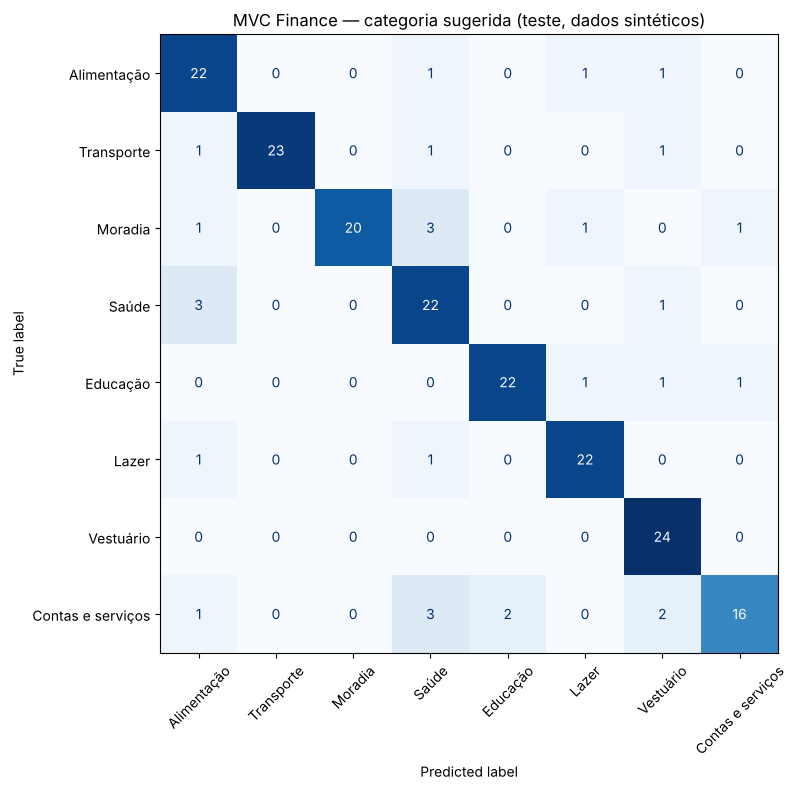

Confiança >= 0.5: sugere em 55.0% dos casos, acerto nesses = 0.891
Confiança >= 0.7: sugere em 7.5% dos casos, acerto nesses = 0.933


In [4]:
modelo = pipe(melhor_C).fit(X_tr, y_tr)
prev = modelo.predict(X_te)
base = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
acc, f1m = accuracy_score(y_te, prev), f1_score(y_te, prev, average='macro')
acc_b = accuracy_score(y_te, base.predict(X_te))
print(f'Acurácia teste: {acc:.4f} | F1 macro: {f1m:.4f} | referência: {acc_b:.4f}')
print(classification_report(y_te, prev, digits=3))
cm = confusion_matrix(y_te, prev, labels=cats)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=cats).plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
plt.title('MVC Finance — categoria sugerida (teste, dados sintéticos)'); plt.tight_layout()
plt.savefig('mvc-finance-matriz.png', dpi=110); plt.show()
proba = modelo.predict_proba(X_te).max(axis=1)
for lim in [0.5, 0.7]:
    m = proba >= lim
    print(f'Confiança >= {lim}: sugere em {m.mean():.1%} dos casos, acerto nesses = {accuracy_score(y_te[m], prev[m]):.3f}')

## 4. Exemplos de sugestão

In [5]:
for t in ['farmacia centro', 'uber pra faculdade', 'conta de luz', 'pix', 'ingresso show']:
    p = modelo.predict_proba([t])[0]; i = p.argmax()
    print(f'{t!r:24} -> {modelo.classes_[i]:18} (confiança {p[i]:.2f})')
json.dump({'acuracia_teste': acc, 'f1_macro_teste': f1m, 'acuracia_referencia': acc_b, 'C': melhor_C,
           'n_treino': len(X_tr), 'n_teste': len(X_te)}, open('resultados_mvc_finance.json', 'w'), indent=2)

'farmacia centro'        -> Saúde              (confiança 0.28)
'uber pra faculdade'     -> Educação           (confiança 0.44)
'conta de luz'           -> Moradia            (confiança 0.68)
'pix'                    -> Vestuário          (confiança 0.18)
'ingresso show'          -> Lazer              (confiança 0.84)


## 5. Interpretação e limites
- A categoria é **sugerida**, nunca imposta: o usuário confirma ou troca no modal "Adicionar Transação". Abaixo de um limiar de confiança, o sistema não sugere nada.
- Títulos genéricos ("pix", "compra") são ambíguos por natureza: nenhum modelo acerta sem mais contexto (valor, método, histórico do próprio usuário).
- Dados sintéticos: o vocabulário foi escolhido por nós. Para uso real seria preciso coletar títulos com consentimento, treinar sem enviar dados a terceiros, avaliar por período (meses futuros) e monitorar erros por perfil de usuário.